# Emulate a TRISHNA L1C from Sentinel-2

## Requirements
- An L1C Sentinel-2 image (SAFE).

## Tutorial objectives
- Load a Sentinel-2 L1C restricted to the TRISHNA-like bands, at 60 m, with GRSdriver.
- Compare with the full S2 image (RGB, TOA spectra).
- Add TRISHNA radiometric noise and look at its impact over water.
- Prepare the product for the GRS atmospheric correction (next tutorial).

## Environment
Use the `sandbox_env` kernel of the CNES JupyterHub. Otherwise install the packages below in your environment (the `trishna_tbx` toolbox: `pip install -e <path>/trishna_tbx`):

`GRSdriver`, `grs`, `GRSl2bgen`, `radcalnet_oc`, `invRrs`, `trishna_tbx`, `rioxarray`, `matplotlib`, `pandas`, `xarray`.

## Resources
The code can be executed with the CPU: 1 core, 4 GB. Run time: ~2 min.

![version](https://img.shields.io/badge/version-11.2026-blue)

## Imports

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

import trishna_tbx
from trishna_tbx import TRISHNA, make_s2
print('trishna_tbx', trishna_tbx.__version__)
from pathlib import Path
THUMB_DIR = Path('../thumbnails').resolve() if Path('../thumbnails').exists() else Path('.').resolve()
# plot style: Times-like serif fonts with LaTeX-style math (STIX, no TeX installation needed),
# larger fonts, minor ticks on all axes
plt.rcParams.update({'figure.dpi': 90, 'font.size': 14, 'font.family': 'STIXGeneral',
                     'mathtext.fontset': 'stix', 'axes.titlesize': 15, 'axes.labelsize': 15,
                     'legend.fontsize': 12, 'xtick.labelsize': 13, 'ytick.labelsize': 13,
                     'xtick.minor.visible': True, 'ytick.minor.visible': True})

from trishna_tbx.emulate import open_s2_l1c_as_trishna, grs_band_set, add_noise, S2_BAND_ORDER
from GRSdriver import Sentinel2Driver

trishna_tbx 0.0.1


## Data
> **Data paths.** On the CNES JupyterHub, point the variables below to the TREX datalake or to your project space. Outside CNES, download Sentinel-2 L1C with the *Access data - Copernicus API* tutorial. Each path can also be set through the environment variable named in the cell.

In [2]:
import os
from pathlib import Path

# ---- edit here (or set the environment variables) ------------------------------------
S2_L1C = os.environ.get('TRISHNA_TBX_S2_L1C',
    '/data/satellite/Sentinel-2/L1C/31TFJ/2025/05/26/'
    'S2B_MSIL1C_20250526T103629_N0511_R008_T31TFJ_20250526T123708.SAFE')
CAMS_FILE = os.environ.get('TRISHNA_TBX_CAMS', '/data/cams/world/cams_forecast_2025-05.nc')
# 30 km box (UTM 31N) over the Berre lagoon and the eastern Gulf of Fos
SUBSET = [(655000, 4800000, 685000, 4830000)]
L2A_DIR = os.environ.get('TRISHNA_TBX_L2A_DIR',
    '/home/harmel/Dropbox/Dropbox/work/projet/unesco/satellite/L2A')  # GRS L2A (beam profile)
L2A_TILE = 'T33PVQ'                      # Lake Chad (southern pool)
L2A_WINDOW = 'y=0:3600,x=0:960'          # 20 m pixel window with water
L2A_DATE = '2022-02-12'                  # date used by the single-image tutorials
# single-image example of the products tutorial: Loire estuary and plume, GRS v3.1.1 (Zarr pyramid,
# local S3 bucket grstbx-s3 of grstbx, read here through its folder)
L2A_EXAMPLE = os.environ.get('TRISHNA_TBX_L2A_EXAMPLE',
    '/data/satellite/s3/grstbx-s3/sentinel-2/l2a/30TWT/2017/04/12/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1/'
    'S2A_MSIL2AGRS_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr')
L2A_EXAMPLE_WINDOW = 'y=2700:5490,x=1500:4500'   # 20 m pixels: estuary, plume, Bourgneuf Bay
L2B_EXAMPLE = os.environ.get('TRISHNA_TBX_L2B_EXAMPLE',   # GRSl2bgen L2B of the same image
    '/data/satellite/s3/grstbx-s3/sentinel-2/l2b/30TWT/2017/04/12/'
    'S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1/'
    'S2A_MSIL2B_20170412T110621_N0500_R137_T30TWT_20231111T110836_V3.1.1.zarr')
AERONET_HYP_DIR = os.environ.get('TRISHNA_TBX_AERONET_HYP', '/DATA/AERONET/OCv3_invRrs/data')
OUTPUT_DIR = Path(os.environ.get('TRISHNA_TBX_OUTPUT', './output')).resolve()
# ---------------------------------------------------------------------------------------
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

> This tutorial complements *Simulate TRISHNA data* (Import Data section), which shows the
> band selection on a full Sentinel-2 image: here we add the 60 m resampling, the GRS-ready
> band configuration and the radiometric noise.

## 1. Load the image
`grs_band_set()` gives the S2 bands to load (TRISHNA proxies B2, B3, B4, B8A, B9, B10, B11
plus B12, kept for the GRS masking only) and the bands processed by GRS (B2, B3, B4, B8A, B11).

In [3]:
band_idx, tbp_idx = grs_band_set(strict=False)
print('loaded   :', [S2_BAND_ORDER[i] for i in band_idx])
print('processed:', [S2_BAND_ORDER[i] for i in tbp_idx])

tri = open_s2_l1c_as_trishna(S2_L1C, resolution=60, subset=SUBSET)
full = Sentinel2Driver(S2_L1C, resolution=60, resolution_angle=60, subset=SUBSET)
full.load_product()
full = full.prod
tri

loaded   : ['B2', 'B3', 'B4', 'B8A', 'B9', 'B10', 'B11', 'B12']
processed: ['B2', 'B3', 'B4', 'B8A', 'B11']


<xarray.Dataset> Size: 25MB
Dimensions:      (x: 501, y: 500, wl: 8, wl_hr: 1950)
Coordinates:
  * x            (x) float64 4kB 6.55e+05 6.55e+05 ... 6.849e+05 6.85e+05
  * y            (y) float64 4kB 4.83e+06 4.83e+06 4.83e+06 ... 4.8e+06 4.8e+06
  * wl           (wl) object 64B 490 560 665 865 945 1375 1610 2190
  * wl_hr        (wl_hr) int64 16kB 400 401 402 403 404 ... 2346 2347 2348 2349
    spatial_ref  int64 8B 0
    time         datetime64[ns] 8B 2025-05-26T10:36:29
Data variables:
    bands        (wl, y, x) float32 8MB 0.1337 0.1208 0.09064 ... nan nan nan
    SRF          (wl, wl_hr) float64 125kB nan nan nan nan ... nan nan nan nan
    wl_true      (wl) float64 64B 492.4 558.9 664.9 ... 1.61e+03 2.186e+03
    vza          (wl, y, x) float32 8MB 9.037 9.042 9.046 9.051 ... nan nan nan
    raa          (wl, y, x) float32 8MB 129.8 129.8 129.8 129.8 ... nan nan nan
    sza          (y, x) float32 1MB 24.56 24.56 24.56 ... 24.18 24.18 24.18
Attributes: (12/50)
    long_name:                           BLUE GREEN RED NARROW_NIR WV SWIR_CI...
    constellation:                       Sentinel-2
    constellation_id:                    S2
    product_path:                        /data/satellite/Sentinel-2/L1C/31TFJ...
    product_name:                        S2B_MSIL1C_20250526T103629_N0511_R00...
    instrument:                          MSI
    ...                                  ...
    solar_irradiance:                    [1874.3  1959.75 1824.93 1512.79 142...
    solar_irradiance_unit:               W/m²/µm
    mean_solar_azimuth:                  152.0484404536862
    mean_solar_zenith_angle:             24.68095425330813
    acquisition_date:                    2025-05-26T10:36:29.024Z
    emulated_sensor:                     TRISHNA (S2 band restriction)

## 2. Plot the product

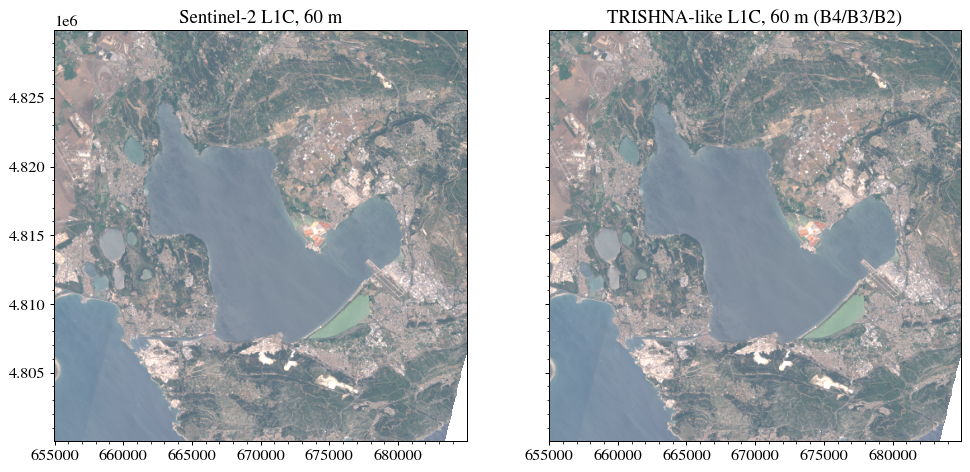

In [4]:
def rgb(prod, wls=(665, 560, 490), gain=3.5):
    img = np.stack([prod.bands.sel(wl=w).values for w in wls], -1) * gain
    return np.clip(img ** (1 / 1.8), 0, 1)

fig, axs = plt.subplots(1, 2, figsize=(13, 6.5), sharex=True, sharey=True)
ext = [float(tri.x.min()), float(tri.x.max()), float(tri.y.min()), float(tri.y.max())]
for ax, p, t in zip(axs, [full, tri], ['Sentinel-2 L1C, 60 m', 'TRISHNA-like L1C, 60 m (B4/B3/B2)']):
    ax.imshow(rgb(p), extent=ext); ax.set_title(t)
fig.savefig(THUMB_DIR / 'emulate_trishna_l1c.png', dpi=70)

## 3. Top-of-atmosphere spectra
Spectra of a water pixel (Berre lagoon), a marine pixel (Gulf of Fos) and a land pixel.
The TRISHNA-like product keeps 8 of the 13 S2 bands. Note that the S2 "WV" band is at
945 nm, not at the TRISHNA 910 nm. On this date the water is strongly affected by sunglint
(TOA reflectance ~0.06 at 1610 nm over water): this is what GRS corrects in the next tutorial.

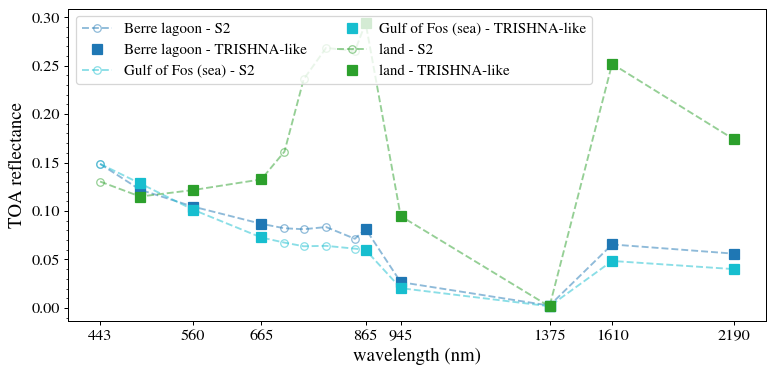

In [5]:
points = {'Berre lagoon': (673000, 4814000), 'Gulf of Fos (sea)': (656000, 4802000), 'land': (680000, 4825000)}
fig, ax = plt.subplots(figsize=(10, 4.5))
for (name, (x, y)), c in zip(points.items(), ['tab:blue', 'tab:cyan', 'tab:green']):
    sf = full.bands.sel(x=x, y=y, method='nearest')
    st = tri.bands.sel(x=x, y=y, method='nearest')
    ax.plot(sf.wl.astype(float), sf, 'o--', c=c, alpha=.5, mfc='none', label=f'{name} - S2')
    ax.plot(st.wl.astype(float), st, 's', c=c, ms=8, label=f'{name} - TRISHNA-like')
ax.set_xscale('log'); ax.set_xticks([443, 560, 665, 865, 945, 1375, 1610, 2190]); ax.xaxis.set_minor_locator(plt.NullLocator())
ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.set_xlabel('wavelength (nm)'); ax.set_ylabel('TOA reflectance'); ax.legend(ncol=2)

## 4. Add TRISHNA radiometric noise
White Gaussian noise from the SNR requirement (`trishna_tbx.sensor`). The S2 image at 60 m is
already an average of several pixels and has very little noise; this step mimics the TRISHNA
noise level. Over water, the spatial variability includes sunglint and real water structures:
the noise is estimated from the pixel-to-pixel differences, `std(diff) / sqrt(2)`, which removes
most of the smooth spatial variations.

In [6]:
rho = tri.bands.sel(wl=[490, 560, 665, 865]).astype(float)
names = ['Blue', 'Green', 'Red', 'NIR']
rho_t = rho.assign_coords(band=('wl', names)).swap_dims(wl='band')
noisy = add_noise(rho_t, tri.sza, sensor=TRISHNA.subset(names), band_dim='band', seed=1)

box = dict(x=slice(670000, 676000), y=slice(4815000, 4810000))   # Berre lagoon
lagoon = rho_t.sel(band='NIR') < 0.12                                # drop the few land pixels
diff_noise = lambda r: (r.where(lagoon).sel(**box).diff('x') / np.sqrt(2)).std(['x', 'y']).values
stats = pd.DataFrame({
    'mean TOA': rho_t.sel(**box).mean(['x', 'y']).values,
    'noise S2 at 60 m': diff_noise(rho_t),
    'noise TRISHNA-like + noise': diff_noise(noisy),
    'TRISHNA requirement': TRISHNA.subset(names).noise_reflectance(float(tri.sza.mean())).values}, index=names)
stats.round(5)

,mean TOA,noise S2 at 60 m,noise TRISHNA-like + noise,TRISHNA requirement
Blue,0.12293,0.00096,0.00141,0.00104
Green,0.10673,0.00119,0.00132,0.00056
Red,0.09184,0.00127,0.00135,0.00045
NIR,0.08817,0.00167,0.00200,0.00105


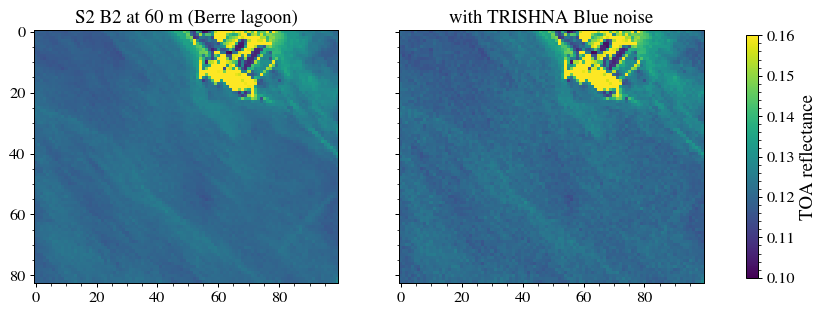

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, r, t in zip(axs, [rho_t, noisy], ['S2 B2 at 60 m (Berre lagoon)', 'with TRISHNA Blue noise']):
    im = ax.imshow(r.sel(band='Blue').sel(**box), vmin=0.10, vmax=0.16, cmap='viridis')
    ax.set_title(t)
fig.colorbar(im, ax=axs, shrink=.7, label='TOA reflectance')

## 5. Save for the next steps
The product (`bands`, angles, `wl_to_process`) can be passed directly to
`grs.Process().execute(prod, ...)`: see *Atmospheric correction with TRISHNA bands (GRS)*.

In [8]:
out = OUTPUT_DIR / 'trishna_like_l1c_subset.nc'
tri_save = tri.drop_vars(['SRF', 'wl_hr'], errors='ignore')
tri_save = tri_save.assign_coords(wl=tri_save.wl.astype(int))
tri_save.attrs = {k: (str(v) if not isinstance(v, (int, float, str)) else v) for k, v in tri_save.attrs.items()}
tri_save.to_netcdf(out)
print(out)

/home/harmel/Dropbox/Dropbox/work/git/satellite_app/trishna_tbx/notebooks/1_importdata/output/trishna_like_l1c_subset.nc


## Take-home messages
- Emulating a TRISHNA L1C from S2 = band selection + 60 m averaging (+ noise). The shift of the
  blue band (11 nm) and the 945 vs 910 nm water-vapour band are **not** corrected by this step.
- At 60 m the noise of the emulated image is lower than the TRISHNA requirement: add it for
  realistic performance studies.